<a href="https://colab.research.google.com/github/Praseedas/example-repo/blob/main/Mutation_analysis.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:
# Install BiocManager if not already present
if (!requireNamespace("BiocManager", quietly = TRUE))
    install.packages("BiocManager")

# Install maftools and TCGAbiolinks
BiocManager::install("maftools", update = FALSE)
BiocManager::install("TCGAbiolinks", update = FALSE)

# Load libraries
library(maftools)
library(TCGAbiolinks)


'getOption("repos")' replaces Bioconductor standard repositories, see
'help("repositories", package = "BiocManager")' for details.
Replacement repositories:
    CRAN: https://cran.rstudio.com

Bioconductor version 3.23 (BiocManager 1.30.27), R 4.6.1 (2026-06-24)

Warning message:
“package(s) not installed when version(s) same as or greater than current; use
  `force = TRUE` to re-install: 'maftools'”
'getOption("repos")' replaces Bioconductor standard repositories, see
'help("repositories", package = "BiocManager")' for details.
Replacement repositories:
    CRAN: https://cran.rstudio.com

Bioconductor version 3.23 (BiocManager 1.30.27), R 4.6.1 (2026-06-24)

Warning message:
“package(s) not installed when version(s) same as or greater than current; use
  `force = TRUE` to re-install: 'TCGAbiolinks'”


In [ ]:
# 1. Query the GDC for LUAD and LUSC somatic mutations using updated parameters
query_luad <- GDCquery(
    project = "TCGA-LUAD",
    data.category = "Simple Nucleotide Variation",
    access = "open",
    data.type = "Masked Somatic Mutation",
    workflow.type = "Aliquot Ensemble Somatic Variant Merging and Masking"
)

query_lusc <- GDCquery(
    project = "TCGA-LUSC",
    data.category = "Simple Nucleotide Variation",
    access = "open",
    data.type = "Masked Somatic Mutation",
    workflow.type = "Aliquot Ensemble Somatic Variant Merging and Masking"
)

# 2. Download the data files to Colab
GDCdownload(query_luad)
GDCdownload(query_lusc)

# 3. Prepare data into standard MAF dataframes
maf_luad_df <- GDCprepare(query_luad)
maf_lusc_df <- GDCprepare(query_lusc)

# 4. Convert dataframes to maftools objects
maf_luad <- read.maf(maf = maf_luad_df)
maf_lusc <- read.maf(maf = maf_lusc_df)


--------------------------------------

o GDCquery: Searching in GDC database

--------------------------------------

Genome of reference: hg38

--------------------------------------------

oo Accessing GDC. This might take a while...

--------------------------------------------

ooo Project: TCGA-LUAD

--------------------

oo Filtering results

--------------------

ooo By access

ooo By data.type

ooo By workflow.type

----------------

oo Checking data

----------------

ooo Checking if there are duplicated cases

ooo Checking if there are results for the query

-------------------

o Preparing output

-------------------

--------------------------------------

o GDCquery: Searching in GDC database

--------------------------------------

Genome of reference: hg38

--------------------------------------------

oo Accessing GDC. This might take a while...

--------------------------------------------

ooo Project: TCGA-LUSC

--------------------

oo Filtering results

----------

Downloading: 55 MB     -Validating
-Silent variants: 47915 
-Summarizing
--Possible FLAGS among top ten genes:
  TTN
  MUC16
  USH2A
  FLG
-Processing clinical data
--Missing clinical data
-Finished in 13.1s elapsed (12.4s cpu) 
-Validating
-Silent variants: 44524 
-Summarizing
--Possible FLAGS among top ten genes:
  TTN
  MUC16
  USH2A
  SYNE1
-Processing clinical data
--Missing clinical data
-Finished in 8.317s elapsed (8.093s cpu) 


In [ ]:
# Compare mutations between LUAD and LUSC
# 'm1' is cohort 1, 'm2' is cohort 2
comparison <- mafCompare(
    m1 = maf_luad,
    m2 = maf_lusc,
    m1Name = "LUAD",
    m2Name = "LUSC",
    minMut = 5 # Only consider genes mutated in at least 5 samples
)

# View the highly significant, subtype-specific mutations
significant_mutations <- comparison$results[comparison$results$adjPval < 0.05, ]
print(head(significant_mutations, 20))


    Hugo_Symbol  LUAD  LUSC         pval          or       ci.up       ci.low
         <char> <num> <num>        <num>       <num>       <num>        <num>
 1:        KRAS   158    11 5.460089e-35 16.68521965  34.5579438 8.9275131985
 2:        TP53   307   438 2.475576e-28  0.24075241   0.3156775 0.1826939339
 3:         TTN   262   374 2.747522e-19  0.33676336   0.4314690 0.2621948369
 4:       STK11    66     3 9.359421e-16 21.60720292 108.2726216 7.0086103735
 5:        EGFR    85    11 1.476959e-14  7.74526664  16.2925393 4.0585743884
 6:       SYNE1    75   165 2.158429e-14  0.31875370   0.4351530 0.2319383883
 7:       KMT2D    40   110 2.926825e-12  0.27429049   0.4066113 0.1820623084
 8:      NFE2L2    19    74 3.539020e-11  0.20239529   0.3444415 0.1137304077
 9:        PTEN    10    55 1.243909e-10  0.14694392   0.2949066 0.0660755813
10:      PLPPR4    72    15 2.477445e-09  4.66183071   8.8723792 2.6071897476
11:      CDKN2A    31    74 3.598539e-07  0.33687595   0.5290723

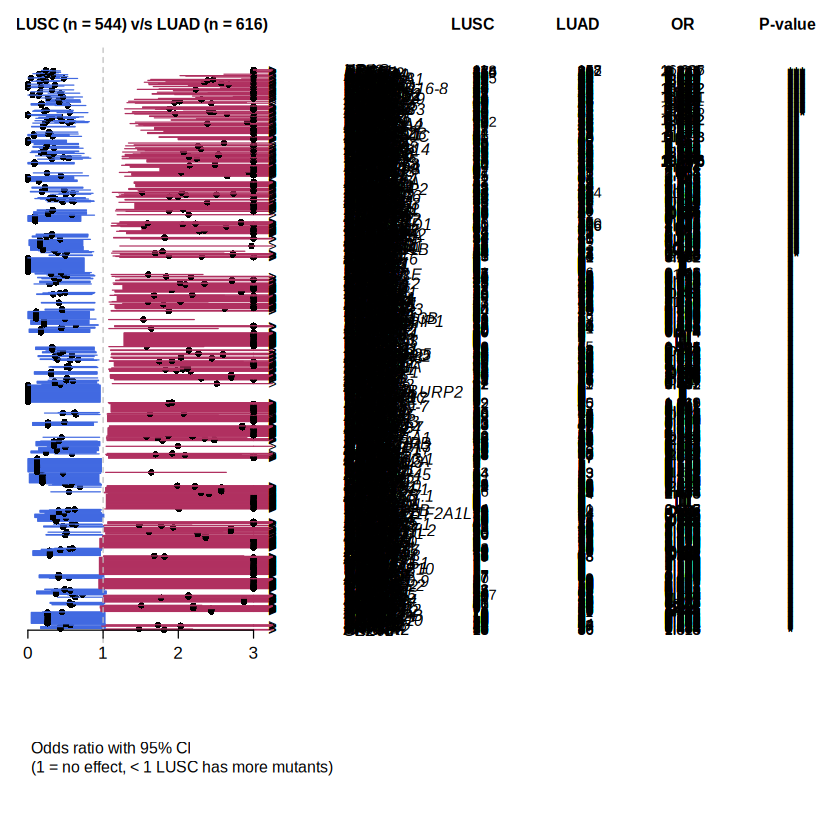

In [ ]:
forestPlot(
    mafCompareRes = comparison,
    pVal = 0.05,
    color = c('royalblue', 'maroon')
)


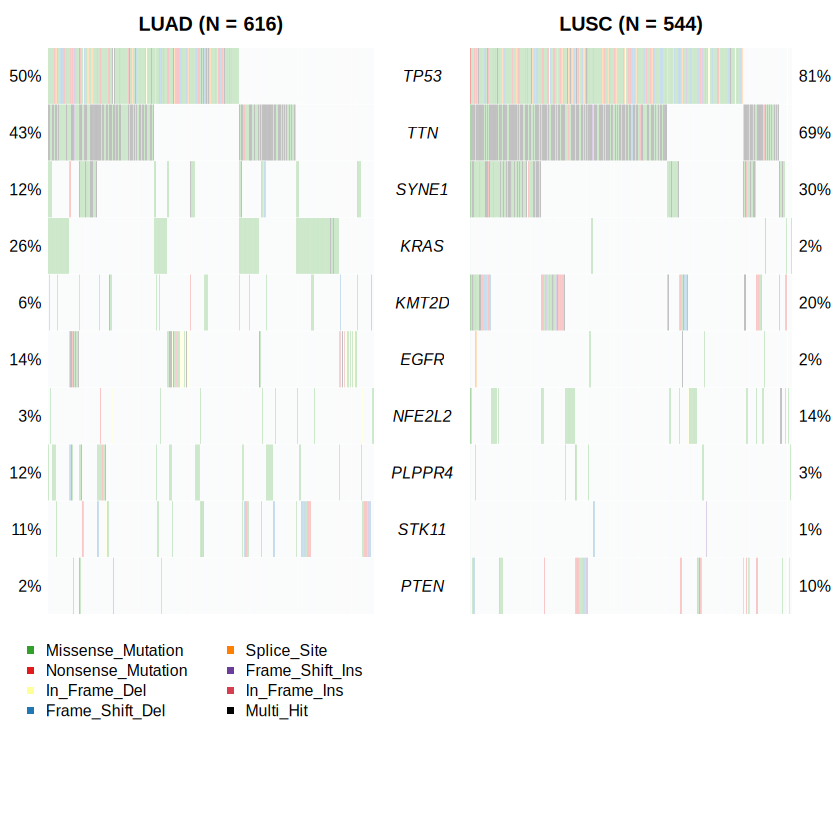

In [ ]:
# Get the top 10 significantly different genes
top_genes <- significant_mutations$Hugo_Symbol[1:10]

coOncoplot(
    m1 = maf_luad,
    m2 = maf_lusc,
    m1Name = "LUAD",
    m2Name = "LUSC",
    genes = top_genes,
    removeNonMutated = TRUE
)


In [ ]:
library(dplyr)
library(ggplot2)
library(tidyr)

# --- STEP 3 & 4: Calculate Mutation Frequencies from your existing dataframes ---
# Extract total unique sample counts in each downloaded dataset
total_luad_samples <- length(unique(maf_luad_df$Tumor_Sample_Barcode))
total_lusc_samples <- length(unique(maf_lusc_df$Tumor_Sample_Barcode))

# LUAD frequency calculation
luad_freq <- maf_luad_df %>%
  distinct(Hugo_Symbol, Tumor_Sample_Barcode) %>%
  count(Hugo_Symbol, name = "Mutated_Samples") %>%
  mutate(Frequency = (Mutated_Samples / total_luad_samples) * 100) %>%
  arrange(desc(Frequency))

# LUSC frequency calculation
lusc_freq <- maf_lusc_df %>%
  distinct(Hugo_Symbol, Tumor_Sample_Barcode) %>%
  count(Hugo_Symbol, name = "Mutated_Samples") %>%
  mutate(Frequency = (Mutated_Samples / total_lusc_samples) * 100) %>%
  arrange(desc(Frequency))

print("--- Top 10 Mutated Genes in LUAD ---")
print(head(luad_freq, 10))
print("--- Top 10 Mutated Genes in LUSC ---")
print(head(lusc_freq, 10))

# --- STEP 5: Identify Common and Specific Genes ---
luad_genes <- unique(luad_freq$Hugo_Symbol)
lusc_genes <- unique(lusc_freq$Hugo_Symbol)

common_genes <- intersect(luad_genes, lusc_genes)
luad_only_genes <- setdiff(luad_genes, lusc_genes)
lusc_only_genes <- setdiff(lusc_genes, luad_genes)

cat("\nNumber of shared mutated genes:", length(common_genes), "\n")
cat("Sample LUAD-specific genes:", head(luad_only_genes), "\n")
cat("Sample LUSC-specific genes:", head(lusc_only_genes), "\n")



Attaching package: ‘dplyr’


The following objects are masked from ‘package:stats’:

    filter, lag


The following objects are masked from ‘package:base’:

    intersect, setdiff, setequal, union




[1] "--- Top 10 Mutated Genes in LUAD ---"
# A tibble: 10 × 3
   Hugo_Symbol Mutated_Samples Frequency
   <chr>                 <int>     <dbl>
 1 TP53                    314      51.0
 2 TTN                     314      51.0
 3 MUC16                   277      45.0
 4 CSMD3                   267      43.3
 5 RYR2                    254      41.2
 6 LRP1B                   224      36.4
 7 USH2A                   212      34.4
 8 ZFHX4                   211      34.3
 9 XIRP2                   178      28.9
10 FLG                     164      26.6
[1] "--- Top 10 Mutated Genes in LUSC ---"
# A tibble: 10 × 3
   Hugo_Symbol Mutated_Samples Frequency
   <chr>                 <int>     <dbl>
 1 TP53                    453      83.3
 2 TTN                     426      78.3
 3 MUC16                   267      49.1
 4 CSMD3                   263      48.3
 5 RYR2                    217      39.9
 6 SYNE1                   208      38.2
 7 USH2A                   206      37.9
 8 LRP1B       

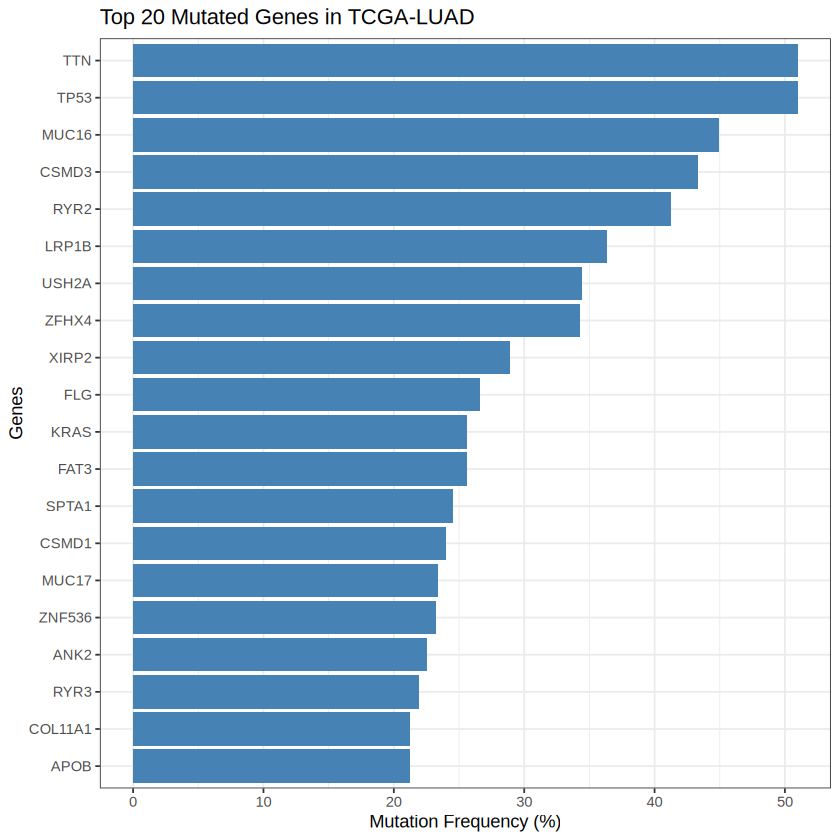

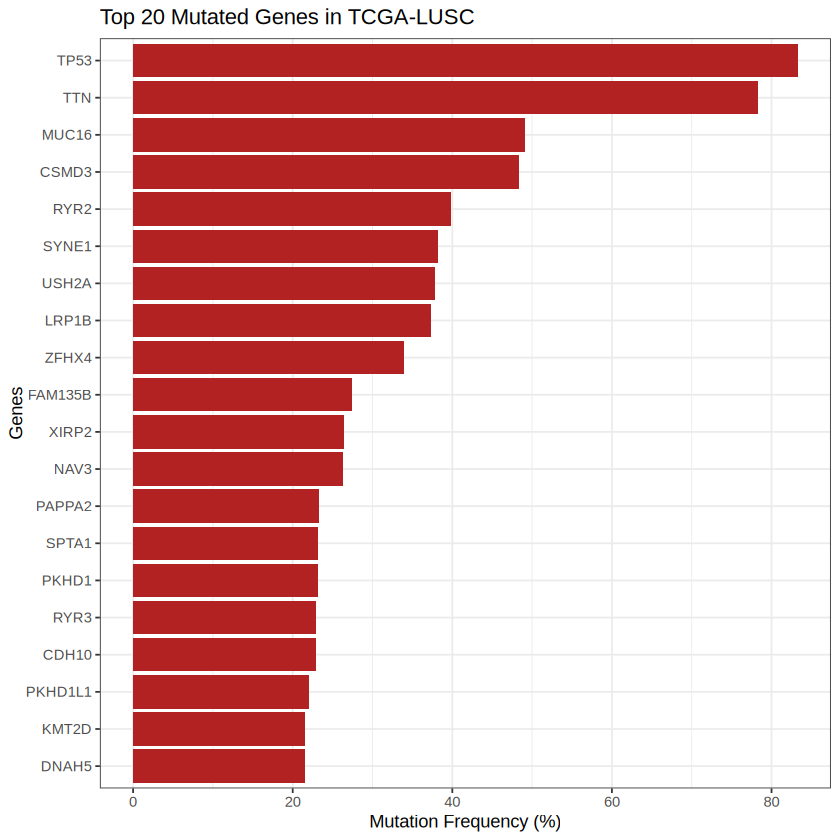

In [ ]:
# Plot for LUAD
ggplot(head(luad_freq, 20), aes(x = reorder(Hugo_Symbol, Frequency), y = Frequency)) +
  geom_col(fill = "steelblue") +
  coord_flip() +
  labs(title = "Top 20 Mutated Genes in TCGA-LUAD", x = "Genes", y = "Mutation Frequency (%)") +
  theme_bw()

# Plot for LUSC
ggplot(head(lusc_freq, 20), aes(x = reorder(Hugo_Symbol, Frequency), y = Frequency)) +
  geom_col(fill = "firebrick") +
  coord_flip() +
  labs(title = "Top 20 Mutated Genes in TCGA-LUSC", x = "Genes", y = "Mutation Frequency (%)") +
  theme_bw()


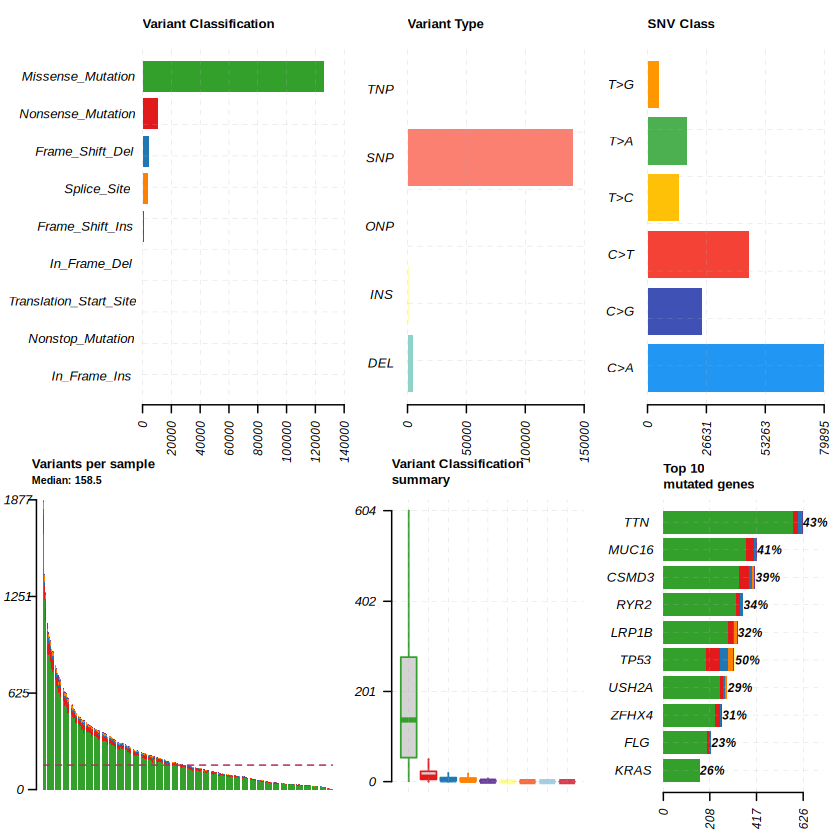

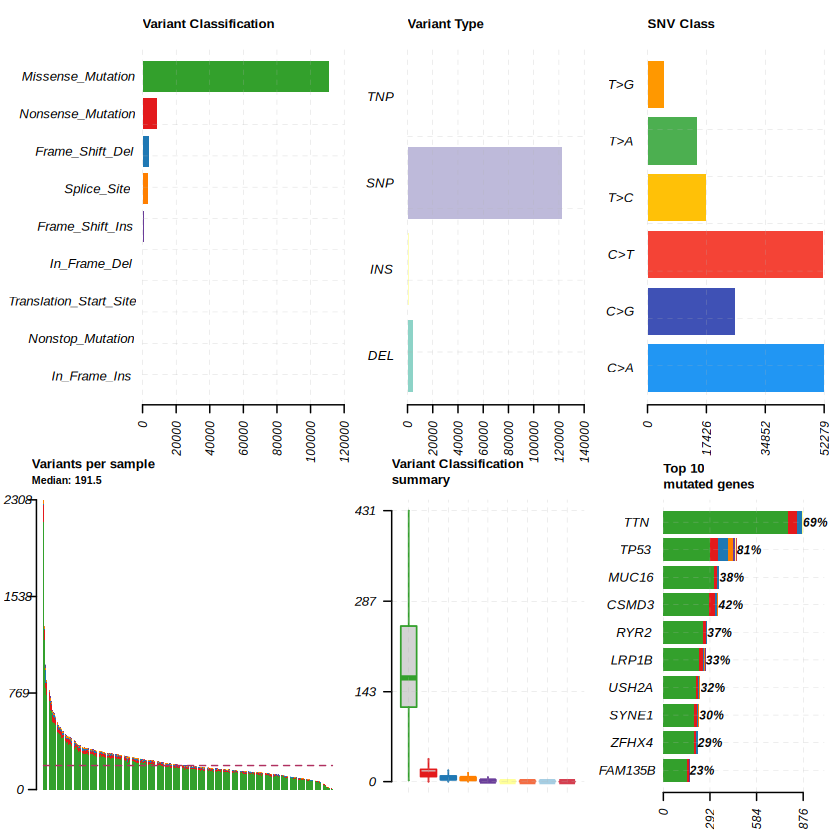

In [ ]:
plotmafSummary(maf = maf_luad, rmOutlier = TRUE, addStat = "median", dashboard = TRUE)
plotmafSummary(maf = maf_lusc, rmOutlier = TRUE, addStat = "median", dashboard = TRUE)


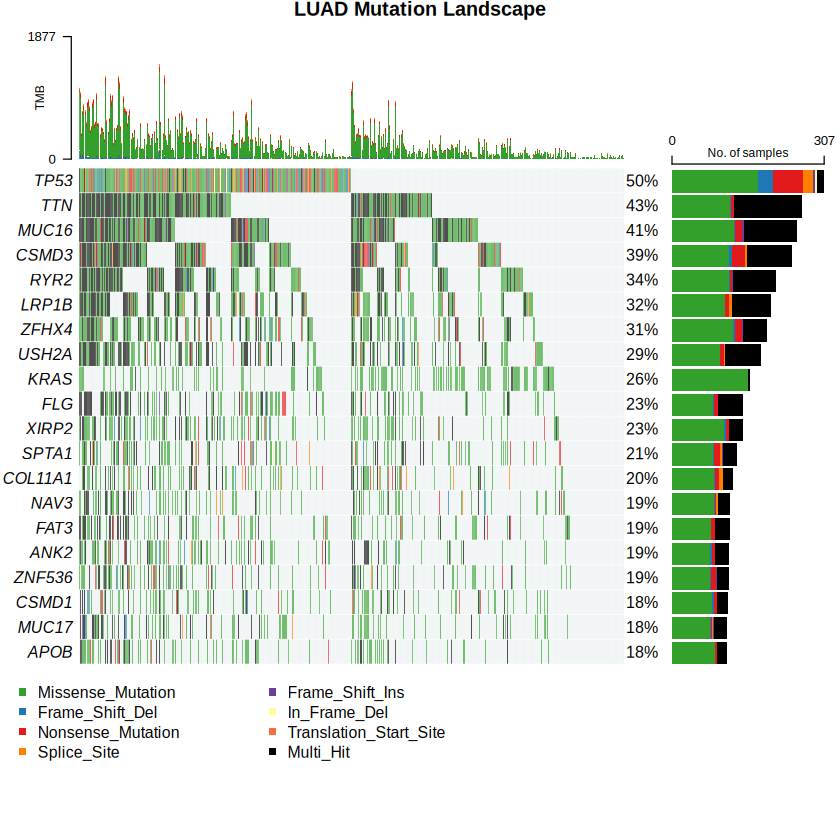

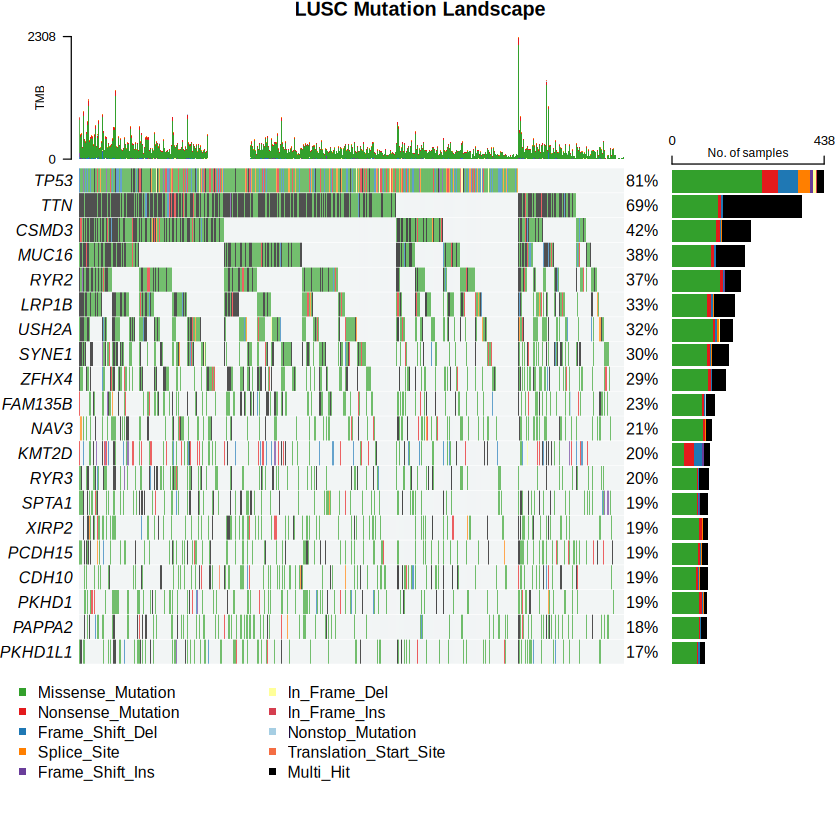

In [ ]:
oncoplot(maf = maf_luad, top = 20, titleText = "LUAD Mutation Landscape")
oncoplot(maf = maf_lusc, top = 20, titleText = "LUSC Mutation Landscape")
